In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import tensorflow as tf
from tensorflow import keras

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (confusion_matrix, classification_report,roc_auc_score,roc_curve)

print("tensorflow",tf.__version__)

tensorflow 2.21.0


In [8]:
np.random.seed(42)
tf.random.set_seed(42)

In [3]:
df = pd.read_csv("breast_cancer_data.csv")

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [7]:
df.shape

(569, 33)

In [10]:
#drop id and unnamed columns
df = df.drop(columns=["id","Unnamed: 32"])

In [11]:
#converting the lables
df["diagnosis"] = df["diagnosis"].map({"M":1,"B":0}).astype(int)

class_names =["benign","malingnant"]

In [12]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [13]:
df.shape

(569, 31)

In [17]:
#check the target distribution

df["diagnosis"].value_counts(normalize=True)*100

,proportion
diagnosis,
0,62.741652
1,37.258348


In [19]:
df.isnull().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


In [26]:
df[["radius_mean","area_worst"]].describe()

,radius_mean,area_worst
count,569.000000,569.000000
mean,14.127292,880.583128
std,3.524049,569.356993
min,6.981000,185.200000
25%,11.700000,515.300000
50%,13.370000,686.500000
75%,15.780000,1084.000000
max,28.110000,4254.000000


In [28]:
#Split the data
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]


In [31]:
X_train_full,X_test,y_train_full,y_test = train_test_split(X,y,test_size =0.2,stratify =y, random_state=42)
X_train,X_val,y_train,y_val = train_test_split(X_train_full,y_train_full,test_size =0.25,stratify =y_train_full, random_state=42)


print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(341, 30)
(114, 30)
(114, 30)


In [32]:
#Scaling the features
scaler = StandardScaler()


In [33]:
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [34]:
X_train.shape[1]

30

In [35]:
#building the model
#Neural Network

#ReLU in the hidden layers and the Sigmoid in the output

#input will be 30
#hidden 1 --> 16
#hidden 2 --> 8
#output


model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(16,activation="relu"),
    keras.layers.Dense(8,activation="relu"),
    keras.layers.Dense(1,activation="sigmoid")
])

In [36]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.1),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [38]:
#Training the model

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",patience=10,restore_best_weights=True
    )

In [39]:
class PrintEvery10(keras.callbacks.Callback):
    def on_epoch_end(self,epoch,logs):
        if (epoch+1)%10==0:
            print(f"epoch {epoch+1:3d}  "
            f"loss {logs ['loss']:.4f}  acc {logs['accuracy']:.4f}"
            f" val_loss {logs['val_loss']:.4f}  val_acc {logs['val_accuracy']:.4f}")

In [40]:
history = model.fit(
    X_train,y_train,
    validation_data=(X_val,y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop,PrintEvery10()],
    verbose =0
)

epoch  10  loss 0.0517  acc 0.9707 val_loss 0.0753  val_acc 0.9825
epoch  20  loss 0.0939  acc 0.9853 val_loss 0.1961  val_acc 0.9298


In [41]:
print("trained for ", len(history.history["loss"]))

trained for  22


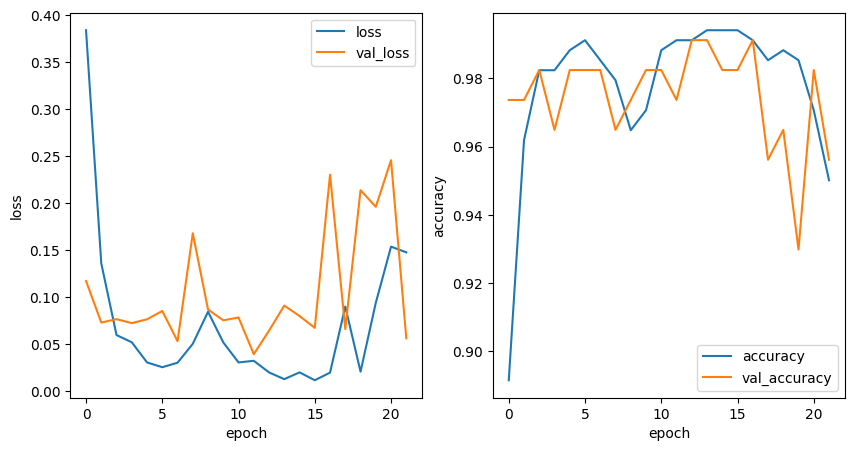

In [42]:
#learning curves

hist = history.history

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.plot(hist["loss"],label="loss")
plt.plot(hist["val_loss"],label="val_loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(hist["accuracy"],label="accuracy")
plt.plot(hist["val_accuracy"],label="val_accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()

plt.show()

In [47]:
#Evaluation on the test set

test_loss,test_acc = model.evaluate(X_test,y_test)
print("test_loss",round(test_loss,3))
print("test_acc",round(test_acc,3))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9737 - loss: 0.2150
test_loss 0.215
test_acc 0.974


In [49]:
y_prob= model.predict(X_test)
y_pred = (y_prob>=0.5).astype(int)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


In [50]:
y_prob[:5]

array([[9.942390e-13],
       [1.000000e+00],
       [2.423739e-06],
       [8.268913e-01],
       [3.884234e-01]], dtype=float32)

In [51]:
y_pred[:5]

array([[0],
       [1],
       [0],
       [1],
       [0]])

In [52]:
#confusion matrix
cm = confusion_matrix(y_test,y_pred)
print(cm)

[[72  0]
 [ 3 39]]


In [53]:
print(classification_report(y_test,y_pred,target_names=class_names))

              precision    recall  f1-score   support

      benign       0.96      1.00      0.98        72
  malingnant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



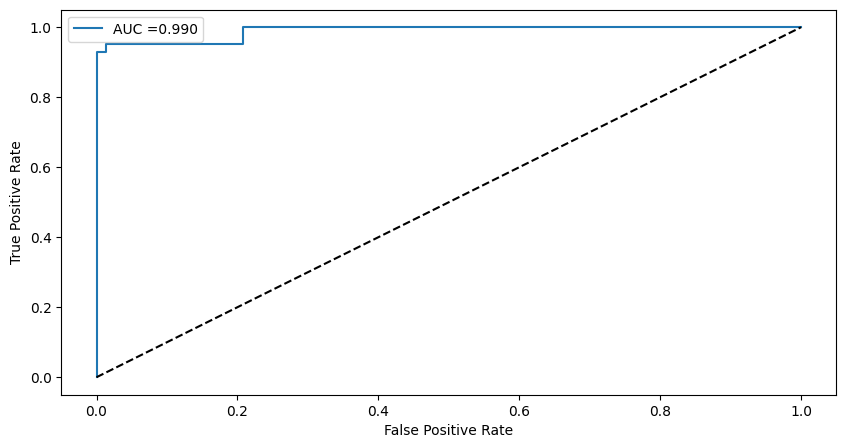

auc 0.99


In [55]:
#roc and auc

auc = roc_auc_score(y_test,y_prob)

fpr,tpr,threshold = roc_curve(y_test,y_prob)
plt.figure(figsize=(10,5))
plt.plot(fpr,tpr,label =f"AUC ={auc:.3f}")
plt.plot([0,1],[0,1],"k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()
print("auc",round(auc,3))


In [56]:
#model saving

import joblib
#saving the model
model.save("breast_cancer_model.keras")
#saving the scaler
joblib.dump(scaler,"breast_cancer_scaler.joblib")

print("Saved: breast_cancer_model.keras, scaler.joblib ")

Saved: breast_cancer_model.keras, scaler.joblib 
